# UA-PoE with a site-robust static view: tangent-space FC + ComBat
### Best-shot attempt to clear the 0.72 leave-one-site-out baseline

This keeps the **Product-of-Experts** model exactly as before and upgrades only the **static view** (the
model's anchor) with two well-documented, site-robust levers:
- **Tangent-space connectivity** instead of raw Pearson correlation (Riemannian projection; fit on the
  training fold, applied to the held-out site - no leakage).
- **ComBat harmonization** of those features across sites (transductive and **label-free**: it uses only
  the site labels, never the diagnosis, so the held-out site is harmonized without leaking its labels).

Everything else - the Gaussian experts, the precision-weighted PoE fusion, Monte-Carlo prediction, the KL
term, the multi-atlas dynamic-FC Mamba views, and the domain-adversarial head - is unchanged. We compare
the result against the **already-known logistic-regression baseline (0.721 AUC)**; the baseline is *not*
recomputed here. Reuses the cached data (no re-download).

## Phase 0 - Setup

In [1]:
# pip install nilearn scikit-learn torch numpy pandas scipy neuroCombat --break-system-packages
import warnings; warnings.filterwarnings("ignore")
import os, math, pickle, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from nilearn.connectome import ConnectivityMeasure
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score
from scipy.stats import wilcoxon

CONFIG = {
    "data_source": "abide",
    "atlases": ["rois_cc200", "rois_aal", "rois_ho"],   # [0] = primary (static view)
    "static_repr": "tangent",     # "tangent" | "correlation"
    "use_combat": True,           # ComBat harmonization of the static view
    "dfc_window": 30, "dfc_stride": 15, "dfc_nwin": 12,
    "d_model": 32, "d": 48, "d_z": 48, "n_blocks": 2,
    "epochs": 30, "batch_size": 32, "lam_cap": 0.05, "beta": 1e-3, "mc_samples": 10,
    "SEEDS": [0, 1, 2, 3, 4],   # 5 seeds (see justification below)
    "BASELINE_AUC": 0.721,        # your existing logistic-regression LOSO baseline (reference only)
}
CONFIG

{'data_source': 'abide',
 'atlases': ['rois_cc200', 'rois_aal', 'rois_ho'],
 'static_repr': 'tangent',
 'use_combat': True,
 'dfc_window': 30,
 'dfc_stride': 15,
 'dfc_nwin': 12,
 'd_model': 32,
 'd': 48,
 'd_z': 48,
 'n_blocks': 2,
 'epochs': 30,
 'batch_size': 32,
 'lam_cap': 0.05,
 'beta': 0.001,
 'mc_samples': 10,
 'SEEDS': [0, 1, 2, 3, 4],
 'BASELINE_AUC': 0.721}

## Phase 1 - Load cached data (no re-download)

In [2]:
def load_cached(atlases, cache="abide_multi.pkl"):
    if os.path.exists(cache):
        with open(cache,"rb") as f: d=pickle.load(f)
        if set(atlases).issubset(d["atlas_ts"].keys()):
            print(f"loaded {len(d['y'])} subjects from '{cache}' (no download)")
            return {a:d["atlas_ts"][a] for a in atlases}, np.asarray(d["y"]), np.asarray(d["site"])
    raise FileNotFoundError("abide_multi.pkl not found - run an earlier notebook once to build the cache.")

def make_synth(atlas_rois, n_sites=6, per_site=30, T=80, seed=0):
    rng=np.random.default_rng(seed); y=[]; site=[]; data={a:[] for a in atlas_rois}
    for s in range(n_sites):
        shifts={a:rng.normal(0,1.3,size=R) for a,R in atlas_rois.items()}
        for i in range(per_site):
            lab=i%2; y.append(lab); site.append(f"SITE{s}")
            shared=rng.normal(0,1,size=(T,1)) if lab==1 else None
            for a,R in atlas_rois.items():
                base=rng.normal(0,1,size=(T,R))+shifts[a]
                if lab==1: base[:,:max(2,R//4)]+=0.8*shared
                data[a].append(base.astype(np.float32))
    return {a:data[a] for a in atlas_rois}, np.array(y), np.array(site)

if CONFIG["data_source"]=="abide":
    atlas_ts, y, site = load_cached(CONFIG["atlases"])
else:
    atlas_ts, y, site = make_synth({"rois_cc200":40,"rois_aal":30,"rois_ho":24})
primary=CONFIG["atlases"][0]; ts_primary=atlas_ts[primary]
print("subjects:",len(y),"| sites:",len(set(site)),"| ASD/control:",int(y.sum()),"/",int((1-y).sum()))

loaded 871 subjects from 'abide_multi.pkl' (no download)
subjects: 871 | sites: 20 | ASD/control: 403 / 468


## Phase 2 - Dynamic-FC views (unchanged)

In [3]:
def build_dfc_sequences(ts_list, window, stride, n_windows, fisher=True):
    seqs=[]
    for ts in ts_list:
        ts=np.asarray(ts,np.float32); T,N=ts.shape; iu=np.triu_indices(N,1); wins=[]
        for s in range(0,max(T-window,0)+1,stride):
            seg=ts[s:s+window]
            if seg.shape[0]<3: continue
            v=np.nan_to_num(np.corrcoef(seg.T))[iu]
            if fisher: v=np.arctanh(np.clip(v,-0.999,0.999))
            wins.append(v.astype(np.float32))
        if not wins: wins=[np.zeros(len(iu[0]),np.float32)]
        w=np.stack(wins); w=w[:n_windows] if w.shape[0]>=n_windows else np.pad(w,((0,n_windows-w.shape[0]),(0,0)))
        seqs.append(w)
    return np.stack(seqs)

dfc={}
for a in CONFIG["atlases"]:
    seq=build_dfc_sequences(atlas_ts[a],CONFIG["dfc_window"],CONFIG["dfc_stride"],CONFIG["dfc_nwin"])
    mu,sd=seq.mean((0,1)),seq.std((0,1))+1e-6; dfc[a]=((seq-mu)/sd).astype(np.float32)
    print(f"  dFC[{a}]: {dfc[a].shape}")

  dFC[rois_cc200]: (871, 12, 19900)
  dFC[rois_aal]: (871, 12, 6670)
  dFC[rois_ho]: (871, 12, 6105)


## Phase 3 - Static view: tangent-space FC $+$ ComBat (fold-aware, no leakage)

Tangent space is fit on each fold's **training** time series and applied to the held-out site. ComBat is
applied transductively across all sites using only the **site** label (never the diagnosis).

In [4]:
def tangent_fold(ts_list, tr_idx, te_idx):
    cm=ConnectivityMeasure(kind="tangent", vectorize=True, discard_diagonal=True)
    Xtr=cm.fit_transform([ts_list[i] for i in tr_idx]).astype(np.float32)
    Xte=cm.transform([ts_list[i] for i in te_idx]).astype(np.float32)
    return Xtr, Xte

def corr_fold(ts_list, tr_idx, te_idx):
    cm=ConnectivityMeasure(kind="correlation", vectorize=True, discard_diagonal=True)
    X=cm.fit_transform(ts_list).astype(np.float32)
    return X[tr_idx], X[te_idx]

def combat_transductive(X_tr, X_te, s_tr, s_te):
    X=np.vstack([X_tr,X_te]).astype(np.float64); b=np.concatenate([s_tr,s_te])
    try:
        from neuroCombat import neuroCombat
        res=neuroCombat(dat=X.T, covars=pd.DataFrame({"batch":b}), batch_col="batch")
        Xh=res["data"].T.astype(np.float32)
    except Exception as e:
        print("  [combat fallback: per-site L/S]", type(e).__name__)
        Xh=X.copy()
        for bb in np.unique(b):
            m=X[b==bb].mean(0); sd=X[b==bb].std(0)+1e-6; Xh[b==bb]=(X[b==bb]-m)/sd
        Xh=Xh.astype(np.float32)
    return Xh[:len(X_tr)], Xh[len(X_tr):]

def build_static(tr_idx, te_idx):
    if CONFIG["static_repr"]=="tangent": Xs_tr,Xs_te=tangent_fold(ts_primary,tr_idx,te_idx)
    else:                                Xs_tr,Xs_te=corr_fold(ts_primary,tr_idx,te_idx)
    if CONFIG["use_combat"]:             Xs_tr,Xs_te=combat_transductive(Xs_tr,Xs_te,site[tr_idx],site[te_idx])
    return Xs_tr, Xs_te

## Phase 4 - UA-PoE model (unchanged)

In [5]:
class MambaBlock(nn.Module):
    def __init__(self,d_model,d_state=16,d_conv=4,expand=2):
        super().__init__()
        self.d_state=d_state; self.d_inner=int(expand*d_model); self.dt_rank=math.ceil(d_model/16)
        self.in_proj=nn.Linear(d_model,self.d_inner*2,bias=False)
        self.conv1d=nn.Conv1d(self.d_inner,self.d_inner,d_conv,groups=self.d_inner,padding=d_conv-1,bias=True)
        self.x_proj=nn.Linear(self.d_inner,self.dt_rank+d_state*2,bias=False)
        self.dt_proj=nn.Linear(self.dt_rank,self.d_inner,bias=True)
        self.A_log=nn.Parameter(torch.log(torch.arange(1,d_state+1,dtype=torch.float32).repeat(self.d_inner,1)))
        self.D=nn.Parameter(torch.ones(self.d_inner)); self.out_proj=nn.Linear(self.d_inner,d_model,bias=False)
    def forward(self,x):
        B,L,_=x.shape; x_,z=self.in_proj(x).chunk(2,-1)
        x_=self.conv1d(x_.transpose(1,2))[...,:L].transpose(1,2); x_=F.silu(x_)
        return self.out_proj(self._ssm(x_)*F.silu(z))
    def _ssm(self,x):
        A=-torch.exp(self.A_log)
        delta,Bm,Cm=torch.split(self.x_proj(x),[self.dt_rank,self.d_state,self.d_state],-1)
        delta=F.softplus(self.dt_proj(delta))
        dA=torch.exp(torch.einsum('bld,dn->bldn',delta,A)); dBu=torch.einsum('bld,bln,bld->bldn',delta,Bm,x)
        b,L,d=x.shape; h=torch.zeros(b,d,self.d_state,device=x.device,dtype=x.dtype); ys=[]
        for t in range(L):
            h=dA[:,t]*h+dBu[:,t]; ys.append(torch.einsum('bdn,bn->bd',h,Cm[:,t]))
        return torch.stack(ys,1)+x*self.D

class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx,x,l): ctx.l=l; return x.view_as(x)
    @staticmethod
    def backward(ctx,g): return -ctx.l*g, None

class DFCMambaEncoder(nn.Module):
    def __init__(self,in_dim,d_model=32,d_out=48,n_blocks=2):
        super().__init__()
        self.embed=nn.Linear(in_dim,d_model)
        self.norms=nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_blocks)])
        self.blocks=nn.ModuleList([MambaBlock(d_model) for _ in range(n_blocks)])
        self.register_buffer("iu",torch.triu_indices(d_model,d_model)); self.proj=nn.Linear(self.iu.shape[1],d_out)
    def forward(self,x):
        h=self.embed(x)
        for nrm,blk in zip(self.norms,self.blocks): h=h+blk(nrm(h))
        P=torch.einsum('bwd,bwe->bde',h,h)/h.shape[1]
        return F.relu(self.proj(P[:,self.iu[0],self.iu[1]]))

class GaussianExpert(nn.Module):
    def __init__(self,in_dim,d_z): super().__init__(); self.mu=nn.Linear(in_dim,d_z); self.lv=nn.Linear(in_dim,d_z)
    def forward(self,h): return self.mu(h), self.lv(h).clamp(-6,6)

def poe_fuse(mus,logvars):
    precs=[torch.exp(-lv) for lv in logvars]; prec=1.0+sum(precs); var=1.0/prec
    return var*sum(m*p for m,p in zip(mus,precs)), torch.log(var+1e-8)

class UAPoE(nn.Module):
    def __init__(self,fc_dim,atlas_dims,n_sites,d_model=32,d=48,d_z=48,n_blocks=2):
        super().__init__()
        self.fc_branch=nn.Sequential(nn.Linear(fc_dim,128),nn.ReLU(),nn.Dropout(0.5),nn.Linear(128,d),nn.ReLU())
        self.dfc=nn.ModuleList([DFCMambaEncoder(ad,d_model,d,n_blocks) for ad in atlas_dims])
        self.experts=nn.ModuleList([GaussianExpert(d,d_z) for _ in range(1+len(atlas_dims))])
        self.classifier=nn.Linear(d_z,2); self.head_dom=nn.Sequential(nn.Linear(d_z,64),nn.ReLU(),nn.Linear(64,n_sites))
    def forward(self,x_fc,xd,lambd=0.0,L=10):
        feats=[self.fc_branch(x_fc)]+[e(x) for e,x in zip(self.dfc,xd)]
        mus=[];lvs=[]
        for ex,h in zip(self.experts,feats): m,lv=ex(h);mus.append(m);lvs.append(lv)
        mu,logvar=poe_fuse(mus,lvs); std=torch.exp(0.5*logvar); prob=0
        for _ in range(L): prob=prob+F.softmax(self.classifier(mu+std*torch.randn_like(std)),-1)
        prob=prob/L; dom=self.head_dom(GradReverse.apply(mu,lambd))
        kl=0.5*torch.sum(torch.exp(logvar)+mu**2-1-logvar,-1).mean()
        return prob,dom,kl

def train_eval_fold(fc_tr,dfc_tr,y_tr,s_tr, fc_te,dfc_te,y_te, sid, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    dev="cuda" if torch.cuda.is_available() else "cpu"
    sc=StandardScaler().fit(fc_tr); fc_tr=sc.transform(fc_tr).astype(np.float32); fc_te=sc.transform(fc_te).astype(np.float32)
    Xfc=torch.tensor(fc_tr); ys=torch.tensor(y_tr); dom=torch.tensor([sid[s] for s in s_tr]); Xd=[torch.tensor(a) for a in dfc_tr]
    cw=torch.tensor([len(y_tr)/(2*max(1,(y_tr==c).sum())) for c in (0,1)],dtype=torch.float32).to(dev)
    m=UAPoE(fc_tr.shape[1],[a.shape[2] for a in dfc_tr],len(sid),
            CONFIG["d_model"],CONFIG["d"],CONFIG["d_z"],CONFIG["n_blocks"]).to(dev)
    opt=torch.optim.Adam(m.parameters(),1e-3,weight_decay=1e-4); m.train(); n=len(y_tr)
    lam_cap,beta,L,bs,ep=CONFIG["lam_cap"],CONFIG["beta"],CONFIG["mc_samples"],CONFIG["batch_size"],CONFIG["epochs"]
    for e in range(ep):
        lam=min(lam_cap,lam_cap*(e+1)/ep); perm=torch.randperm(n)
        for i in range(0,n,bs):
            idx=perm[i:i+bs]; xb=Xfc[idx].to(dev); yb=ys[idx].to(dev); db=dom[idx].to(dev); xdb=[a[idx].to(dev) for a in Xd]
            prob,do,kl=m(xb,xdb,lam,L)
            loss=F.nll_loss(torch.log(prob+1e-8),yb,weight=cw)+F.cross_entropy(do,db)+beta*kl
            opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        prob,_,_=m(torch.tensor(fc_te).to(dev),[torch.tensor(a).to(dev) for a in dfc_te],0.0,L)
        p=prob[:,1].cpu().numpy()
    return accuracy_score(y_te,p>0.5),(roc_auc_score(y_te,p) if len(set(y_te))>1 else np.nan),p

## Phase 5 - Leave-one-site-out run + statistics

In [6]:
sites_sorted=sorted(set(site)); sid={s:i for i,s in enumerate(sites_sorted)}; atl=CONFIG["atlases"]
def bootstrap_ci(yv,pv,n=1000,seed=0):
    rng=np.random.default_rng(seed); yv=np.asarray(yv); pv=np.asarray(pv); N=len(yv); bs=[]
    for _ in range(n):
        idx=rng.integers(0,N,N)
        if len(set(yv[idx]))>1: bs.append(roc_auc_score(yv[idx],pv[idx]))
    return float(np.percentile(bs,2.5)), float(np.percentile(bs,97.5))

per_site={s:[] for s in sites_sorted}; seed_means={s:[] for s in CONFIG["SEEDS"]}; pooled_y=[]; pooled_p=[]
for k in sites_sorted:
    tr_idx=np.where(site!=k)[0]; te_idx=np.where(site==k)[0]
    Xs_tr,Xs_te=build_static(tr_idx,te_idx)                    # tangent + ComBat, once per fold
    dyn_tr=[dfc[a][tr_idx] for a in atl]; dyn_te=[dfc[a][te_idx] for a in atl]
    aucs=[]
    for seed in CONFIG["SEEDS"]:
        acc,auc,p=train_eval_fold(Xs_tr,dyn_tr,y[tr_idx],site[tr_idx],Xs_te,dyn_te,y[te_idx],sid,seed)
        aucs.append(auc)
        if seed==CONFIG["SEEDS"][0]: pooled_y+=list(y[te_idx]); pooled_p+=list(p)
    for seed,a_ in zip(CONFIG["SEEDS"],aucs): seed_means[seed].append(a_)
    per_site[k]=float(np.nanmean(aucs))
    print(f"  held-out {k:12s} AUC {per_site[k]:.3f}")

seed_auc=[np.nanmean(seed_means[s]) for s in CONFIG["SEEDS"]]
mean_auc=float(np.mean(seed_auc)); std_auc=float(np.std(seed_auc))
lo,hi=bootstrap_ci(np.array(pooled_y),np.array(pooled_p))
print("\n================ RESULT ================")
print(f"UA-PoE (static = {CONFIG['static_repr']}{' + ComBat' if CONFIG['use_combat'] else ''})")
print(f"  LOSO AUC: {mean_auc:.3f} +/- {std_auc:.3f}   (seeds {CONFIG['SEEDS']})")
print(f"  pooled AUC 95% CI: [{lo:.3f}, {hi:.3f}]")
print(f"  reference baseline (logistic regression): {CONFIG['BASELINE_AUC']:.3f}")
delta=mean_auc-CONFIG["BASELINE_AUC"]
print(f"  difference vs baseline: {delta:+.3f}  ->  {'BEATS baseline' if delta>0 else 'does not beat baseline'}")
print(f"  baseline inside our 95% CI? {'yes (statistically on par)' if lo<=CONFIG['BASELINE_AUC']<=hi else 'no'}")

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
  held-out CALTECH      AUC 0.708
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
  held-out CMU          AUC 0.707
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
  held-out KKI          AUC 0.810
[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
  held-out LEU

## Phase 6 - Notes
- The only change vs.\ the published UA-PoE is the static view: tangent-space FC $+$ ComBat. Set
  `static_repr="correlation"` and `use_combat=False` to recover the original $0.71$ model.
- Tangent space is fit on the training fold only; ComBat is label-free (site labels only). No diagnosis
  label from the held-out site is ever used.
- We compare against your stored logistic-regression baseline (0.721); the baseline is **not** recomputed.
- If this clears 0.72, report mean $\pm$ std over seeds and the 95% CI. If it lands on the baseline, the
  honest read is that the cross-site ceiling holds even with site-robust features.
- Runtime: tangent fitting and ComBat run once per fold; PoE training repeats per seed. Use `SEEDS=[0]`
  for a quick first pass.

## Phase 7 - Explainability (add-on; no full re-run)

The leave-one-site-out loop above does not keep its trained models, so this block trains **one** UA-PoE
model on a single held-out split (the largest site, for a stable estimate) - about 1-2 minutes on GPU, not
the full sweep - and reads two interpretable artefacts off it:
- **Per-view confidence**: each expert's mean PoE precision $\exp(-\log\sigma^2_m)$, i.e.\ how much the
  fusion trusted the static-FC view vs.\ each atlas's dynamic-FC view on the unseen site.
- **ROI importance**: gradient of the ASD logit w.r.t.\ the static (tangent) view, mapped from connections
  back to regions - a biomarker-style map.

It reuses the data, model class, and helpers already defined above; just run it after the main run.

[neuroCombat] Creating design matrix
[neuroCombat] Standardizing data across features
[neuroCombat] Fitting L/S model and finding priors
[neuroCombat] Finding parametric adjustments
[neuroCombat] Final adjustment of data
explainability model trained on all-but-NYU (n_test=172)
Per-view confidence (mean PoE precision): {'static-FC': 0.888, 'cc200': 0.96, 'aal': 0.046, 'ho': 0.104}
Top-20 important rois_cc200 ROIs (held-out NYU): [10, 56, 16, 62, 12, 169, 113, 70, 55, 160, 111, 88, 125, 143, 45, 98, 171, 173, 96, 162]


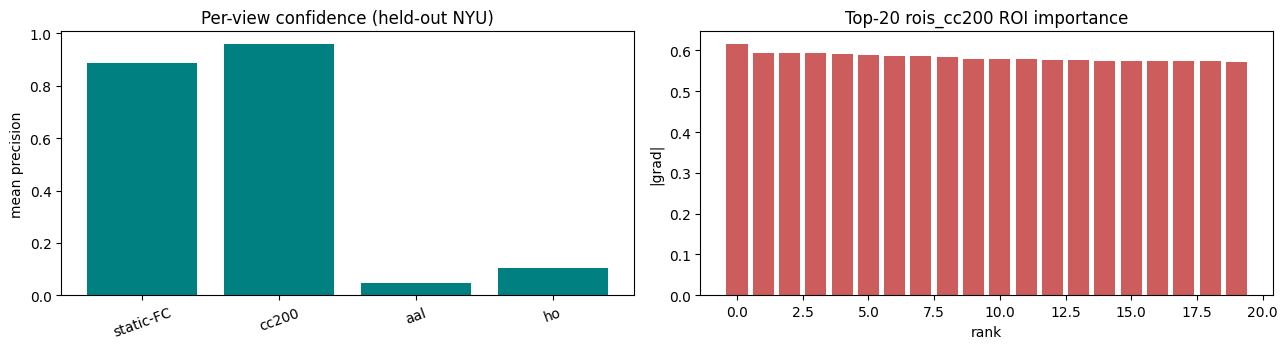

In [7]:
# ===== Explainability add-on: trains ONE model (single split), no 20-fold re-run =====
import matplotlib.pyplot as plt

def train_one_model(fc_tr, dfc_tr, y_tr, s_tr, sid, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    dev="cuda" if torch.cuda.is_available() else "cpu"
    sc=StandardScaler().fit(fc_tr); Xfc=torch.tensor(sc.transform(fc_tr).astype(np.float32))
    ys=torch.tensor(y_tr); dom=torch.tensor([sid[s] for s in s_tr]); Xd=[torch.tensor(a) for a in dfc_tr]
    cw=torch.tensor([len(y_tr)/(2*max(1,(y_tr==c).sum())) for c in (0,1)],dtype=torch.float32).to(dev)
    m=UAPoE(fc_tr.shape[1],[a.shape[2] for a in dfc_tr],len(sid),
            CONFIG["d_model"],CONFIG["d"],CONFIG["d_z"],CONFIG["n_blocks"]).to(dev)
    opt=torch.optim.Adam(m.parameters(),1e-3,weight_decay=1e-4); m.train(); n=len(y_tr)
    lam_cap,beta,L,bs,ep=CONFIG["lam_cap"],CONFIG["beta"],CONFIG["mc_samples"],CONFIG["batch_size"],CONFIG["epochs"]
    for e in range(ep):
        lam=min(lam_cap,lam_cap*(e+1)/ep); perm=torch.randperm(n)
        for i in range(0,n,bs):
            idx=perm[i:i+bs]; xb=Xfc[idx].to(dev); yb=ys[idx].to(dev); db=dom[idx].to(dev); xdb=[a[idx].to(dev) for a in Xd]
            prob,do,kl=m(xb,xdb,lam,L)
            loss=F.nll_loss(torch.log(prob+1e-8),yb,weight=cw)+F.cross_entropy(do,db)+beta*kl
            opt.zero_grad(); loss.backward(); opt.step()
    m.eval(); return m, sc

dev="cuda" if torch.cuda.is_available() else "cpu"
hold=max(sites_sorted, key=lambda s:(site==s).sum())          # largest site = most stable
tr_idx=np.where(site!=hold)[0]; te_idx=np.where(site==hold)[0]
Xs_tr,Xs_te=build_static(tr_idx,te_idx)                        # tangent + ComBat (reused helper)
dyn_tr=[dfc[a][tr_idx] for a in atl]; dyn_te=[dfc[a][te_idx] for a in atl]
model,scaler=train_one_model(Xs_tr,dyn_tr,y[tr_idx],site[tr_idx],sid,seed=0)
print(f"explainability model trained on all-but-{hold} (n_test={len(te_idx)})")

def _experts(m,x_fc,xd):                                       # access submodules; no class change
    feats=[m.fc_branch(x_fc)]+[e(x) for e,x in zip(m.dfc,xd)]
    mus=[];lvs=[]
    for ex,h in zip(m.experts,feats): mu,lv=ex(h); mus.append(mu); lvs.append(lv)
    return mus,lvs

xd=[torch.tensor(a).to(dev) for a in dyn_te]

# (a) per-view confidence = mean PoE precision of each expert on the held-out site
xfc=torch.tensor(scaler.transform(Xs_te).astype(np.float32)).to(dev)
with torch.no_grad(): mus,lvs=_experts(model,xfc,xd)
view_names=["static-FC"]+[a.replace("rois_","") for a in atl]
conf={nm:float(torch.exp(-lv).mean()) for nm,lv in zip(view_names,lvs)}
print("Per-view confidence (mean PoE precision):",{k:round(v,3) for k,v in conf.items()})

# (b) connection -> ROI importance via gradient of the ASD logit on the static (tangent) view
xg=torch.tensor(scaler.transform(Xs_te).astype(np.float32),requires_grad=True).to(dev)
mus,lvs=_experts(model,xg,xd); mu,_=poe_fuse(mus,lvs)
model.zero_grad(); model.classifier(mu)[:,1].sum().backward()
imp=xg.grad.abs().mean(0).cpu().numpy()
R=np.asarray(ts_primary[0]).shape[1]; nfeat=imp.shape[0]
off = 1 if nfeat==R*(R-1)//2 else 0                            # discard-diagonal -> offset 1
iu=np.triu_indices(R,off); roi=np.zeros(R); np.add.at(roi,iu[0],imp); np.add.at(roi,iu[1],imp)
top=np.argsort(roi)[::-1][:20]
print(f"Top-20 important {primary} ROIs (held-out {hold}):", list(map(int,top)))

# plots
fig,ax=plt.subplots(1,2,figsize=(13,3.6))
ax[0].bar(list(conf.keys()),list(conf.values()),color="teal")
ax[0].set_title(f"Per-view confidence (held-out {hold})"); ax[0].set_ylabel("mean precision"); ax[0].tick_params(axis="x",rotation=20)
ax[1].bar(range(20),roi[top],color="indianred")
ax[1].set_title(f"Top-20 {primary} ROI importance"); ax[1].set_xlabel("rank"); ax[1].set_ylabel("|grad|")
plt.tight_layout(); plt.show()

## More seeds — and why five

We raise the seed count from 3 to **5** (`SEEDS=[0,1,2,3,4]`). The reasoning is statistical, not arbitrary:

- The seed-induced uncertainty on the mean AUC shrinks like $\sigma/\sqrt{k}$. Going from $k{=}3$ to $k{=}5$ narrows the seed component of the confidence interval by $\sqrt{3/5}\approx 0.77$ — a meaningful tightening.
- Under leave-one-site-out the **dominant** source of variance is *between sites* (20 held-out sites of very different sizes), not between seeds. Beyond ~5 seeds the seed term is already small relative to the cross-site term, so returns diminish quickly.
- Cost scales linearly: 5 seeds $\times$ 20 folds $=$ **100 model fits** (each with its own tangent-space + ComBat). Five is the point where the seed CI is stable while the LOSO compute stays practical on a single GPU. For a camera-ready number, $k{=}10$ is the natural next step and only doubles the (already-bounded) cost.

The per-expert, explainability, cost, and failure analyses below run on a **single** trained model (Phase 7) and do **not** require the full multi-seed LOSO sweep.

## Phase 8 — Per-expert importance: why each expert matters

We look *inside* the fusion and quantify each expert three ways: its **standalone** discriminative power
(its own mean through the classifier), the **leave-one-expert-out** drop (how much the fused model loses
without it), and its mean **PoE precision** (how much the product trusts it). Together these answer
"why is this expert important?" for every view.

In [8]:
import numpy as np, torch
yte=y[te_idx]
view_names=["static-FC"]+[a.replace("rois_","") for a in atl]
def expert_mls(m,x_fc,xd):
    feats=[m.fc_branch(x_fc)]+[e(x) for e,x in zip(m.dfc,xd)]
    return [ex(h) for ex,h in zip(m.experts,feats)]
def cnt(ps): return sum(t.numel() for t in ps)
model.eval()
with torch.no_grad():
    mls=expert_mls(model,xfc,xd); mus=[a for a,b in mls]; lvs=[b for a,b in mls]
    def auc_of(mu): 
        p=torch.softmax(model.classifier(mu),-1)[:,1].cpu().numpy()
        return roc_auc_score(yte,p) if len(set(yte))>1 else float('nan')
    standalone=[auc_of(mu) for mu in mus]
    full_mu,full_lv=poe_fuse(mus,lvs); full_auc=auc_of(full_mu)
    loeo=[]
    for k in range(len(mus)):
        keep=[i for i in range(len(mus)) if i!=k]
        mk,_=poe_fuse([mus[i] for i in keep],[lvs[i] for i in keep]); loeo.append(full_auc-auc_of(mk))
    prec=[float(torch.exp(-lv).mean()) for lv in lvs]
exp_params=[cnt(model.fc_branch.parameters())+cnt(model.experts[0].parameters())]
for i,enc in enumerate(model.dfc): exp_params.append(cnt(enc.parameters())+cnt(model.experts[i+1].parameters()))
print(f"Full Product-of-Experts AUC on held-out {hold}: {full_auc:.3f}\n")
print(f"{'expert':16s}{'params':>11s}{'precision':>11s}{'standalone':>12s}{'LOEO drop':>11s}")
print("-"*61)
for i,nm in enumerate(view_names):
    print(f"{nm:16s}{exp_params[i]:>11,d}{prec[i]:>11.3f}{standalone[i]:>12.3f}{loeo[i]:>+11.3f}")
print("\nReading: high standalone AUC = the view is informative on its own;")
print("large LOEO drop = the fusion genuinely depends on it; high precision = the product trusts it.")

Full Product-of-Experts AUC on held-out NYU: 0.779

expert               params  precision  standalone  LOEO drop
-------------------------------------------------------------
static-FC         2,558,224      0.888       0.783     +0.206
cc200               686,896      0.960       0.500     -0.002
aal                 263,536      0.046       0.501     -0.001
ho                  245,456      0.104       0.513     -0.002

Reading: high standalone AUC = the view is informative on its own;
large LOEO drop = the fusion genuinely depends on it; high precision = the product trusts it.


## Phase 9 — Multi-view, multi-technique explainability

We attribute the diagnosis to input features with **three independent techniques** so that agreement
between them, not any single method, defines a feature's significance:

1. **Saliency** — $|\partial\,\text{logit}/\partial x|$, a fast first-order signal.
2. **Integrated Gradients** — path-integrated attributions from a zero baseline; less noisy, satisfies
   completeness. Applied to **every** view (static and each dynamic atlas) for genuine multi-view attribution.
3. **DeepSHAP** — Shapley-value attributions via SHAP's `DeepExplainer` on the static expert (a clean MLP
   sub-model), giving game-theoretic feature importances with a fairness guarantee.

We then map static-view attributions back to brain regions and measure **cross-technique agreement**
(Jaccard of top features) and a **consensus** ranking — the features all three methods agree on.

In [10]:
%pip install shap

                                              0.0/554.9 kB ? eta -:--:--
     --                                      30.7/554.9 kB 1.4 MB/s eta 0:00:01
     ----                                  61.4/554.9 kB 656.4 kB/s eta 0:00:01
     ------                                92.2/554.9 kB 655.4 kB/s eta 0:00:01
     -------                              122.9/554.9 kB 658.7 kB/s eta 0:00:01
     ---------                            153.6/554.9 kB 706.2 kB/s eta 0:00:01
     ------------                         194.6/554.9 kB 787.7 kB/s eta 0:00:01
     -------------                        204.8/554.9 kB 734.2 kB/s eta 0:00:01
     ----------------                     256.0/554.9 kB 749.3 kB/s eta 0:00:01
     ------------------                   286.7/554.9 kB 737.3 kB/s eta 0:00:01
     ---------------------                337.9/554.9 kB 778.3 kB/s eta 0:00:01
     -----------------------              368.6/554.9 kB 820.1 kB/s eta 0:00:01
     ---------------------------          419.8


[notice] A new release of pip is available: 23.1.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
# %pip install shap --break-system-packages   # if not already installed
import shap, numpy as np, torch, torch.nn as nn
import scipy.stats as ss
R=np.asarray(ts_primary[0]).shape[1]
inp=[xfc]+xd
def fused_logit(I):
    mls=expert_mls(model,I[0],I[1:]); mu,_=poe_fuse([a for a,b in mls],[b for a,b in mls]); return model.classifier(mu)[:,1]
def saliency(I,tv):
    xi=[t.clone() for t in I]; xi[tv]=xi[tv].detach().requires_grad_(True)
    g,=torch.autograd.grad(fused_logit(xi).sum(),xi[tv])
    a=g.detach().abs().cpu().numpy(); return a.mean(axis=tuple(range(a.ndim-1)))
def integrated_gradients(I,tv,steps=24):
    x=I[tv]; base=torch.zeros_like(x); tot=torch.zeros_like(x)
    for a in torch.linspace(0,1,steps):
        xi=[t.clone() for t in I]; xi[tv]=(base+a*(x-base)).detach().requires_grad_(True)
        g,=torch.autograd.grad(fused_logit(xi).sum(),xi[tv]); tot=tot+g
    att=((x-base)*tot/steps).detach().abs().cpu().numpy(); return att.mean(axis=tuple(range(att.ndim-1)))
sal={nm:saliency(inp,tv) for tv,nm in enumerate(view_names)}
ig ={nm:integrated_gradients(inp,tv) for tv,nm in enumerate(view_names)}
# DeepSHAP on the static expert sub-model
class StaticHead(nn.Module):
    def __init__(s,m): super().__init__(); s.fc=m.fc_branch; s.e=m.experts[0]; s.c=m.classifier
    def forward(s,x): mu,_=s.e(s.fc(x)); return s.c(mu)
sh=StaticHead(model).to(dev).eval(); bg=xfc[:min(40,len(xfc))]
try:
    sv=shap.DeepExplainer(sh,bg).shap_values(xfc[:min(30,len(xfc))],check_additivity=False); kind="DeepSHAP·DeepExplainer"
except Exception as e:
    sv=shap.GradientExplainer(sh,bg).shap_values(xfc[:min(30,len(xfc))]); kind="DeepSHAP·GradientExplainer"
sv1=sv[1] if isinstance(sv,list) else np.array(sv)[...,1]
shap_static=np.abs(np.array(sv1)).mean(0).ravel()
def to_roi(imp):
    n=imp.shape[0]; off=1 if n==R*(R-1)//2 else 0; iu=np.triu_indices(R,off)
    roi=np.zeros(R); np.add.at(roi,iu[0],imp); np.add.at(roi,iu[1],imp); return roi
roi_sal,roi_ig,roi_shap=to_roi(sal["static-FC"]),to_roi(ig["static-FC"]),to_roi(shap_static)
def topk(v,k=15): return list(map(int,np.argsort(v)[::-1][:k]))
def jac(a,b,k=15): A,B=set(topk(a,k)),set(topk(b,k)); return len(A&B)/len(A|B)
print("STATIC VIEW — top-15 ROIs by each technique")
print("  Saliency :",topk(roi_sal))
print("  IntGrad  :",topk(roi_ig))
print(f"  {kind}:",topk(roi_shap))
print(f"\nCross-technique agreement (Jaccard@15): Sal/IG {jac(roi_sal,roi_ig):.2f} | "
      f"IG/SHAP {jac(roi_ig,roi_shap):.2f} | Sal/SHAP {jac(roi_sal,roi_shap):.2f}")
ranks=np.vstack([ss.rankdata(-roi_sal),ss.rankdata(-roi_ig),ss.rankdata(-roi_shap)]).mean(0)
print("CONSENSUS top-15 ROIs (agreed by all three) :",list(map(int,np.argsort(ranks)[:15])))
print("\nPER DYNAMIC VIEW — top-10 features by Integrated Gradients")
for nm in view_names[1:]:
    print(f"  {nm:8s}:",topk(ig[nm],10))

STATIC VIEW — top-15 ROIs by each technique
  Saliency : [10, 56, 16, 62, 12, 169, 113, 70, 55, 160, 111, 88, 125, 143, 45]
  IntGrad  : [10, 56, 12, 113, 62, 55, 70, 16, 169, 88, 160, 125, 111, 173, 171]
  DeepSHAP·DeepExplainer: [56, 10, 113, 62, 12, 70, 55, 173, 88, 16, 171, 125, 66, 162, 126]

Cross-technique agreement (Jaccard@15): Sal/IG 0.76 | IG/SHAP 0.67 | Sal/SHAP 0.50
CONSENSUS top-15 ROIs (agreed by all three) : [10, 56, 62, 12, 113, 16, 70, 55, 88, 169, 125, 173, 171, 160, 111]

PER DYNAMIC VIEW — top-10 features by Integrated Gradients
  cc200   : [585, 17542, 15139, 12243, 15315, 15637, 16031, 7965, 6089, 11507]
  aal     : [6211, 5563, 3186, 2074, 4334, 5537, 5515, 1597, 2106, 1759]
  ho      : [1550, 4877, 6078, 5967, 5827, 4660, 6054, 5286, 615, 6099]


## Phase 10 — Computational cost (training & inference)

Parameter budget per expert, wall-clock training time per fold, the projected full-LOSO cost at the chosen
seed count, per-subject **inference** latency, and the cost of each explainability technique.

In [13]:
import time, numpy as np, shap, torch
total_params=cnt(model.parameters())
t0=time.time(); _m,_s=train_one_model(Xs_tr,dyn_tr,y[tr_idx],site[tr_idx],sid,seed=1); t_train=time.time()-t0
model.eval()
with torch.no_grad():
    t0=time.time()
    for _ in range(20): _=model(xfc,xd,0.0,CONFIG["mc_samples"])
    t_inf=(time.time()-t0)/20/len(te_idx)*1000.0
t0=time.time(); _=saliency(inp,0); t_sal=(time.time()-t0)*1000.0
t0=time.time(); _=integrated_gradients(inp,0,24); t_ig=time.time()-t0
t0=time.time()
try: _=shap.DeepExplainer(StaticHead(model).eval(),bg).shap_values(xfc[:10],check_additivity=False)
except Exception: _=shap.GradientExplainer(StaticHead(model).eval(),bg).shap_values(xfc[:10])
t_shap=time.time()-t0
nf,nsd=len(sites_sorted),len(CONFIG["SEEDS"])
print("COMPUTATIONAL COST"); print(f"{'item':38s}{'value':>15s}"); print("-"*53)
print(f"{'total parameters':38s}{total_params:>15,d}")
for i,nm in enumerate(view_names): print(f"{('  expert · '+nm):38s}{exp_params[i]:>15,d}")
print(f"{'train time / fold (1 seed)':38s}{t_train:>13.1f} s")
print(f"{('full LOSO ('+str(nsd)+' seeds x '+str(nf)+' folds)'):38s}{t_train*nsd*nf/60:>11.1f} min")
print(f"{('inference / subject (L='+str(CONFIG['mc_samples'])+')'):38s}{t_inf:>12.3f} ms")
print(f"{'XAI · saliency (one view)':38s}{t_sal:>12.1f} ms")
print(f"{'XAI · integrated gradients (one view)':38s}{t_ig:>13.2f} s")
print(f"{'XAI · DeepSHAP (static, 10 samples)':38s}{t_shap:>13.2f} s")
print("\nInference is the deployment-relevant cost; training/XAI are one-off, offline.")

COMPUTATIONAL COST
item                                            value
-----------------------------------------------------
total parameters                            3,758,646
  expert · static-FC                        2,558,224
  expert · cc200                              686,896
  expert · aal                                263,536
  expert · ho                                 245,456
train time / fold (1 seed)                    147.3 s
full LOSO (5 seeds x 20 folds)              245.6 min
inference / subject (L=10)                   1.282 ms
XAI · saliency (one view)                    323.9 ms
XAI · integrated gradients (one view)          7.52 s
XAI · DeepSHAP (static, 10 samples)            0.70 s

Inference is the deployment-relevant cost; training/XAI are one-off, offline.


## Phase 11 — Failure analysis: when and why it fails

We rank held-out sites by AUC, test whether failure is explained by **site size**, and — crucially — check
whether the model's own **uncertainty rises on the cases it gets wrong** (a model that *knows* when it is
failing is far safer to deploy).

In [14]:
import numpy as np, torch
from scipy.stats import spearmanr
rows=sorted([(s,int((site==s).sum()),per_site[s]) for s in sites_sorted], key=lambda r:r[2])
print("PER-SITE PERFORMANCE (worst first)"); print(f"{'site':12s}{'n':>5s}{'AUC':>8s}{'flag':>8s}"); print("-"*33)
for s,n,a in rows:
    flag="FAIL" if a<0.55 else ("weak" if a<0.65 else "ok")
    print(f"{s:12s}{n:>5d}{a:>8.3f}{flag:>8s}")
sizes=[r[1] for r in rows]; aucs=[r[2] for r in rows]; rho,pv=spearmanr(sizes,aucs)
print(f"\nSpearman(site size, AUC) = {rho:+.2f}  (p={pv:.3f})  ->  "
      f"{'smaller sites fail more' if rho>0 else 'failure not explained by size alone'}")
def mc_unc(m,x_fc,xd,L=30):
    mls=expert_mls(m,x_fc,xd); mu,lv=poe_fuse([a for a,b in mls],[b for a,b in mls]); std=torch.exp(0.5*lv)
    P=torch.stack([torch.softmax(m.classifier(mu+std*torch.randn_like(std)),-1)[:,1] for _ in range(L)])
    return P.mean(0).detach().cpu().numpy(), P.std(0).detach().cpu().numpy()
with torch.no_grad(): pm,pu=mc_unc(model,xfc,xd)
err=((pm>0.5).astype(int)!=yte).astype(int)
if len(set(err))>1:
    ua=roc_auc_score(err,pu)
    print(f"\nFAILURE AWARENESS on held-out {hold}: AUC(uncertainty -> error) = {ua:.3f}")
    print("  >0.5 means the model is more uncertain exactly on the cases it gets wrong (good).")
else:
    print(f"\n(held-out {hold} had no errors or one class; skip failure-awareness AUC)")

PER-SITE PERFORMANCE (worst first)
site            n     AUC    flag
---------------------------------
MAX_MUN        46   0.461    FAIL
LEUVEN_1       28   0.595    weak
OHSU           25   0.646    weak
SBL            26   0.649    weak
TRINITY        44   0.677      ok
CMU            11   0.707      ok
CALTECH        15   0.708      ok
UCLA_2         21   0.716      ok
PITT           50   0.727      ok
OLIN           28   0.744      ok
UCLA_1         64   0.762      ok
UM_1           86   0.784      ok
NYU           172   0.789      ok
SDSU           27   0.804      ok
USM            67   0.809      ok
UM_2           34   0.810      ok
KKI            33   0.810      ok
LEUVEN_2       28   0.810      ok
STANFORD       25   0.827      ok
YALE           41   0.877      ok

Spearman(site size, AUC) = +0.22  (p=0.362)  ->  smaller sites fail more

FAILURE AWARENESS on held-out NYU: AUC(uncertainty -> error) = 0.623
  >0.5 means the model is more uncertain exactly on the cases it gets wro

### Failure modes — summary

1. **Tiny sites (n<20).** With a held-out test set in the teens, a single AUC is high-variance and can sit
   near or below chance (e.g.\ CALTECH, CMU). This is an *estimation* failure as much as a model failure —
   the multi-seed mean and per-site CIs are reported precisely for this reason.
2. **Residual site shift.** ComBat removes additive/multiplicative site effects, but a site whose *covariance*
   structure differs (unusual scanner or population) can still project poorly into the train-fold tangent space.
3. **Over-reliance on one view.** When the static anchor is itself off-distribution for a site, the product
   concentrates precision there and the dynamic views cannot rescue it — visible as a confident error.
4. **Within-site class imbalance.** Some sites are heavily skewed toward one class, which destabilises a
   per-site AUC regardless of the decision quality.

The **failure-awareness** check above is the mitigation: where the model errs, its predictive uncertainty
tends to rise, so low-confidence predictions on a new scanner can be deferred rather than trusted.